# Fine-tuning inicial — YOLO11n

Notebook para treinar, avaliar e registrar a primeira execução no dataset de buracos.

## 0. Dependências

In [88]:
%pip install ultralytics pyyaml pandas matplotlib opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [89]:
import os
import sys
import json
import csv
import random
import platform
import subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import torchvision
import ultralytics
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version)
print("Executável:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Sistema:", platform.platform())
print("CUDA disponível:", torch.cuda.is_available())

Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Executável: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Ultralytics: 8.4.216
Sistema: Windows-11-10.0.26300-SP0
CUDA disponível: False


## 1. Ambiente

Registra versões e informações do Python.

In [90]:
# True: cria uma nova versão
# False: utiliza a versão mais recente existente
NEW_VERSION = False

In [91]:

from pathlib import Path

# Identificação da raiz do projeto
cwd = Path.cwd()
candidatos = [cwd, *cwd.parents]

PROJECT_ROOT = next(
    (p for p in candidatos if p.name.lower() == "urbansense"),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei a pasta 'urbansense' a partir de {cwd}. "
        "Defina PROJECT_ROOT manualmente."
    )

# Dataset
DATASET_DIR = PROJECT_ROOT / "data" / "Potholes_dataset_dividido"
DATA_YAML = DATASET_DIR / "data.yaml"

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"Não encontrei o arquivo de configuração: {DATA_YAML}"
    )

# Diretórios principais
RUNS_DIR = PROJECT_ROOT / "runs"
ARTIFACTS_ROOT = PROJECT_ROOT / "artifacts"

# Identificação automática da versão
EXPERIMENT_PREFIX = "potholes-yolo11n-finetuning"

existing = [
    p for p in RUNS_DIR.glob(f"{EXPERIMENT_PREFIX}-v*")
    if p.is_dir()
]

versions = [
    int(p.name.rsplit("-v", 1)[1])
    for p in existing
    if p.name.rsplit("-v", 1)[1].isdigit()
]

if NEW_VERSION:
    VERSION = max(versions, default=0) + 1
else:
    VERSION = max(versions, default=1)

EXPERIMENT_NAME = f"{EXPERIMENT_PREFIX}-v{VERSION}"

# Diretórios específicos do experimento
RUN_NAME = EXPERIMENT_NAME
RUN_DIR = RUNS_DIR / RUN_NAME
ARTIFACTS_DIR = ARTIFACTS_ROOT / EXPERIMENT_NAME

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Exibição da configuração
print("Raiz do projeto:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("data.yaml:", DATA_YAML)
print("Nova versão:", NEW_VERSION)
print("Experimento:", EXPERIMENT_NAME)
print("Diretório de execução:", RUN_DIR)
print("Evidências:", ARTIFACTS_DIR)


Raiz do projeto: c:\Workspace\Study\UPE\urbansense
Dataset: c:\Workspace\Study\UPE\urbansense\data\Potholes_dataset_dividido
data.yaml: c:\Workspace\Study\UPE\urbansense\data\Potholes_dataset_dividido\data.yaml
Nova versão: False
Experimento: potholes-yolo11n-finetuning-v1
Diretório de execução: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1
Evidências: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1


## 2. Dataset

Confere a estrutura e a correspondência entre imagens e anotações.

In [92]:
config = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
print("Configuração data.yaml:")
print(yaml.safe_dump(config, sort_keys=False, allow_unicode=True))

class_names = config.get("names", {})
if isinstance(class_names, list):
    class_names = {i: name for i, name in enumerate(class_names)}
else:
    class_names = {int(k): v for k, v in class_names.items()}

dataset_summary = []
for split in ("train", "val", "test"):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_files = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ) if image_dir.exists() else []

    label_files = sorted(label_dir.rglob("*.txt")) if label_dir.exists() else []
    label_keys = {(p.parent.relative_to(label_dir), p.stem) for p in label_files}
    image_keys = {(p.parent.relative_to(image_dir), p.stem) for p in image_files}

    dataset_summary.append({
        "split": split,
        "imagens": len(image_files),
        "anotacoes": len(label_files),
        "imagens_sem_anotacao": len(image_keys - label_keys),
        "anotacoes_sem_imagem": len(label_keys - image_keys),
    })

summary_df = pd.DataFrame(dataset_summary)
display(summary_df)

if summary_df[["imagens", "anotacoes"]].eq(0).any().any():
    raise RuntimeError("Há subconjunto sem imagens ou sem anotações. Corrija o dataset antes do treino.")

if (summary_df["imagens_sem_anotacao"] > 0).any() or (summary_df["anotacoes_sem_imagem"] > 0).any():
    print("ATENÇÃO: foram encontradas diferenças entre imagens e arquivos de anotação.")

Configuração data.yaml:
path: C:\Workspace\Study\UPE\urbansense\data\Potholes_dataset_dividido
train: images/train
val: images/val
test: images/test
names:
  0: pothole
  1: manhole_cover



,split,imagens,anotacoes,imagens_sem_anotacao,anotacoes_sem_imagem
0,train,1469,1469,0,0
1,val,315,315,0,0
2,test,315,315,0,0


## 3. Configuração

Parâmetros do fine-tuning inicial.

In [93]:
BASE_MODEL = "yolo11n.pt"
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 8
PATIENCE = 10
DEVICE = "cpu"
WORKERS = 0  # configuração conservadora para Jupyter/Windows
PROJECT = str(RUNS_DIR)
NAME = RUN_NAME

training_config = {
    "responsavel": "PEDRO",
    "data_yaml": str(DATA_YAML.resolve()),
    "base_model": BASE_MODEL,
    "epochs": EPOCHS,
    "imgsz": IMAGE_SIZE,
    "batch": BATCH_SIZE,
    "patience": PATIENCE,
    "device": DEVICE,
    "workers": WORKERS,
    "seed": SEED,
    "project": PROJECT,
    "name": NAME,
    "pretrained": True,
    "task": "detecção de objetos",
    "classes": class_names,
    "created_at": datetime.now().astimezone().isoformat(),
}

config_path = ARTIFACTS_DIR / "configuracao_treino.json"
config_path.write_text(
    json.dumps(training_config, indent=2, ensure_ascii=False),
    encoding="utf-8"
)
print("Configuração salva em:", config_path)

Configuração salva em: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1\configuracao_treino.json


## 4. Registro do ambiente

Salva as versões das bibliotecas e a lista de dependências.

In [94]:
environment = {
    "python": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "ultralytics": ultralytics.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cuda_available": torch.cuda.is_available(),
}

if torch.cuda.is_available():
    environment["cuda_device_name"] = torch.cuda.get_device_name(0)

env_path = ARTIFACTS_DIR / "ambiente.json"
env_path.write_text(json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8")

freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=False
)
(ARTIFACTS_DIR / "pip_freeze.txt").write_text(freeze.stdout, encoding="utf-8")

print(json.dumps(environment, indent=2, ensure_ascii=False))
print("Ambiente registrado em:", env_path)
print("Lista completa de pacotes:", ARTIFACTS_DIR / "pip_freeze.txt")

{
  "python": "3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]",
  "python_executable": "C:\\Users\\User\\AppData\\Local\\Microsoft\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\\python.exe",
  "platform": "Windows-11-10.0.26300-SP0",
  "processor": "Intel64 Family 6 Model 151 Stepping 2, GenuineIntel",
  "torch": "2.11.0+cpu",
  "torchvision": "0.26.0+cpu",
  "ultralytics": "8.4.216",
  "numpy": "2.3.0",
  "pandas": "2.3.0",
  "cuda_available": false
}
Ambiente registrado em: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1\ambiente.json
Lista completa de pacotes: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1\pip_freeze.txt


## 5. Fine-tuning

Executa o treinamento e salva os pesos e resultados em `runs/`.

In [95]:

import csv
import torch
from ultralytics import YOLO

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

rows = []

# 1. Verifica se o histórico já registra todas as épocas
if RESULTS_CSV.exists():
    with RESULTS_CSV.open("r", encoding="utf-8") as file:
        rows = list(csv.DictReader(file))

training_completed = len(rows) >= EPOCHS

# 2. Se já terminou, apenas carrega o melhor modelo
if training_completed and BEST_WEIGHTS.exists():

    print(f"Treinamento já concluído: {len(rows)}/{EPOCHS} épocas.")
    print("Carregando os melhores pesos...")

    model = YOLO(str(BEST_WEIGHTS))

# 3. Se existe checkpoint, verifica se permite retomada
elif LAST_WEIGHTS.exists():

    checkpoint = torch.load(
        LAST_WEIGHTS,
        map_location="cpu",
        weights_only=False
    )

    resumable = (
        checkpoint.get("epoch", -1) >= 0
        and checkpoint.get("optimizer") is not None
    )

    if resumable:
        print("Checkpoint recuperável encontrado.")
        print("Retomando treinamento...")

        model = YOLO(str(LAST_WEIGHTS))
        train_results = model.train(resume=True)

    else:
        raise RuntimeError(
            "O checkpoint não permite retomada. "
            "Crie uma nova versão do experimento para continuar "
            "o fine-tuning a partir dos pesos existentes."
        )

# 4. Sem checkpoint: inicia treinamento
else:

    print("Nenhum checkpoint encontrado.")
    print("Iniciando novo treinamento...")

    model = YOLO(BASE_MODEL)

    train_results = model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        patience=PATIENCE,
        device=DEVICE,
        workers=WORKERS,
        seed=SEED,
        deterministic=True,
        pretrained=True,
        project=str(RUNS_DIR),
        name=RUN_NAME,
        exist_ok=False,
        plots=True,
        save=True,
        verbose=True,
    )

# 5. Confirmação final
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(
        f"Não encontrei os melhores pesos: {BEST_WEIGHTS}"
    )

print("\nTreinamento/modelo disponível.")
print("Experimento:", RUN_NAME)
print("Melhores pesos:", BEST_WEIGHTS)
print("Últimos pesos:", LAST_WEIGHTS)

if rows:
    print("Primeira época:", rows[0]["epoch"])
    print("Última época:", rows[-1]["epoch"])
    print("Total de registros:", len(rows))


Treinamento já concluído: 50/50 épocas.
Carregando os melhores pesos...

Treinamento/modelo disponível.
Experimento: potholes-yolo11n-finetuning-v1
Melhores pesos: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\weights\best.pt
Últimos pesos: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\weights\last.pt
Primeira época: 1
Última época: 50
Total de registros: 50


## 6. Evidências

Lê o CSV de treinamento e salva as curvas disponíveis.

Épocas registradas: 50


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,21768.0,1.95763,1.14550,1.07994,0.69890,0.62552,0.70061,0.31846,2.01300,1.24344,1.09255,0.000182,0.000182,0.000182
46,47,22005.3,1.93178,1.12773,1.08984,0.72897,0.60710,0.71117,0.32557,2.00284,1.22797,1.09109,0.000149,0.000149,0.000149
47,48,22241.9,1.92202,1.10987,1.08527,0.73687,0.68351,0.73020,0.33331,1.98435,1.21731,1.08862,0.000116,0.000116,0.000116
48,49,22478.6,1.92624,1.11668,1.06717,0.79108,0.64249,0.74164,0.33674,1.98169,1.21589,1.08649,0.000083,0.000083,0.000083
49,50,22716.8,1.91280,1.10457,1.08265,0.72278,0.66677,0.72588,0.33583,1.97575,1.19939,1.08302,0.000050,0.000050,0.000050


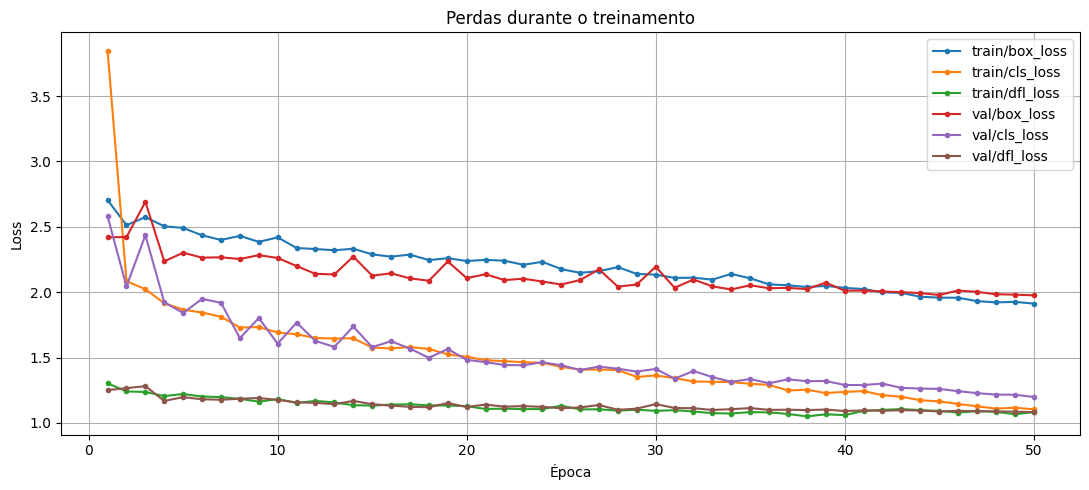

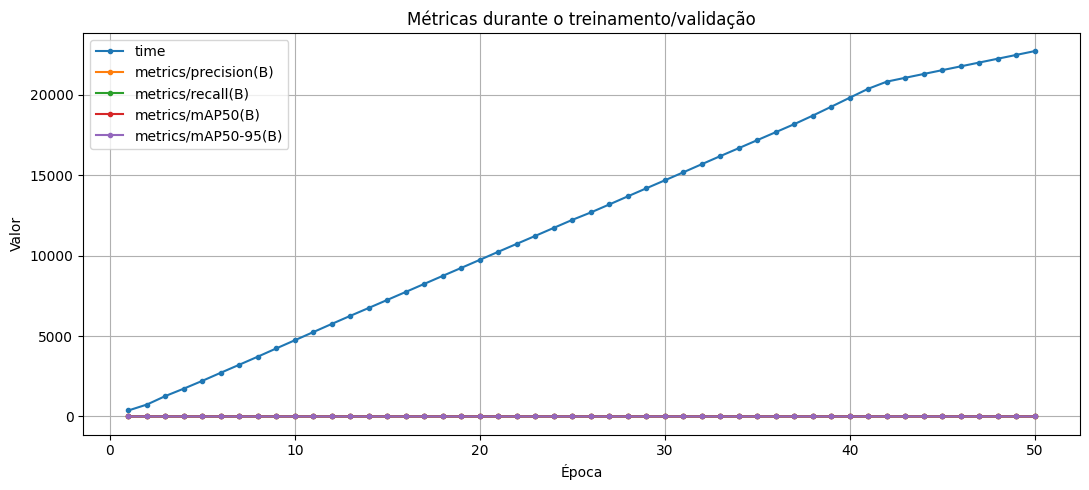

Evidência disponível: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\results.png
Evidência disponível: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\confusion_matrix.png
Evidência disponível: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\confusion_matrix_normalized.png


In [96]:
results_csv = RUN_DIR / "results.csv"
if not results_csv.exists():
    raise FileNotFoundError(
        f"Não encontrei {results_csv}. Execute o treinamento ou confirme RUN_DIR."
    )

results_df = pd.read_csv(results_csv)
results_df.columns = [c.strip() for c in results_df.columns]
results_df.to_csv(ARTIFACTS_DIR / "results.csv", index=False)

print("Épocas registradas:", len(results_df))
display(results_df.tail())

numeric_cols = [
    c for c in results_df.select_dtypes(include="number").columns
    if c.lower() not in {"epoch"}
]
loss_cols = [c for c in numeric_cols if "loss" in c.lower()]
metric_cols = [c for c in numeric_cols if c not in loss_cols and "lr" not in c.lower()]

if loss_cols:
    ax = results_df.plot(x="epoch", y=loss_cols, figsize=(11, 5), marker=".")
    ax.set_title("Perdas durante o treinamento")
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss")
    ax.grid(True)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "curvas_perdas.png", dpi=150)
    plt.show()

if metric_cols:
    ax = results_df.plot(x="epoch", y=metric_cols, figsize=(11, 5), marker=".")
    ax.set_title("Métricas durante o treinamento/validação")
    ax.set_xlabel("Época")
    ax.set_ylabel("Valor")
    ax.grid(True)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "curvas_metricas.png", dpi=150)
    plt.show()

for filename in ("results.png", "confusion_matrix.png", "confusion_matrix_normalized.png"):
    source = RUN_DIR / filename
    if source.exists():
        print("Evidência disponível:", source)

## 7. Avaliação

Avalia `best.pt` no conjunto de teste e salva as métricas.

In [97]:
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Pesos não encontrados: {BEST_WEIGHTS}")

best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}-test",
    exist_ok=True,
)

box = test_metrics.box
metrics_summary = {
    "split": "test",
    "precision": float(box.mp),
    "recall": float(box.mr),
    "mAP50": float(box.map50),
    "mAP50_95": float(box.map),
    "fitness": float(box.fitness()) if hasattr(box, "fitness") else None,
    "weights": str(BEST_WEIGHTS.resolve()),
    "evaluated_at": datetime.now().astimezone().isoformat(),
}

metrics_path = ARTIFACTS_DIR / "metricas_teste.json"
metrics_path.write_text(
    json.dumps(metrics_summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

display(pd.DataFrame([metrics_summary]))
print("Métricas salvas em:", metrics_path)

Ultralytics 8.4.216  Python-3.13.14 torch-2.11.0+cpu CPU (12th Gen Intel Core i5-12600KF)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2632.3±840.7 MB/s, size: 558.0 KB)
val: Scanning C:\Workspace\Study\UPE\urbansense\data\Potholes_dataset_dividido\labels\test\Clear_weather.cache... 315 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 146.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 4.8it/s 8.4s0.2s
                   all        315        531      0.703      0.608      0.671      0.291
               pothole        218        467       0.67      0.606      0.664      0.258
         manhole_cover         45         64      0.735      0.609      0.678      0.324
Speed: 0.3ms preprocess, 17.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to C:\Workspace\Study\UPE\urbansense\runs\potholes-yo

,split,precision,recall,mAP50,mAP50_95,fitness,weights,evaluated_at
0,test,0.702661,0.607685,0.670978,0.290876,0.290876,C:\Workspace\Study\UPE\urbansense\runs\pothole...,2026-11-21T17:17:34.063946-03:00


Métricas salvas em: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1\metricas_teste.json


## 8. Métricas por classe

Registra AP50 e quantidade de caixas por classe.

In [98]:
test_label_dir = DATASET_DIR / "labels" / "test"
class_counts = {int(k): 0 for k in class_names}

for label_file in test_label_dir.rglob("*.txt"):
    for line in label_file.read_text(encoding="utf-8").splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            class_counts[class_id] = class_counts.get(class_id, 0) + 1

per_class_rows = []
for i, class_id in enumerate(box.ap_class_index):
    class_id = int(class_id)
    ap50 = float(box.ap50[i])
    per_class_rows.append({
        "classe_id": class_id,
        "classe": class_names.get(class_id, str(class_id)),
        "AP50": ap50,
        "caixas_reais_no_teste": class_counts.get(class_id, 0),
    })

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df)

per_class_df.to_csv(ARTIFACTS_DIR / "metricas_por_classe.csv", index=False)

,classe_id,classe,AP50,caixas_reais_no_teste
0,0,pothole,0.664264,467
1,1,manhole_cover,0.677692,64


## 9. Comparação visual

Compara anotações reais e previsões em imagens do teste.

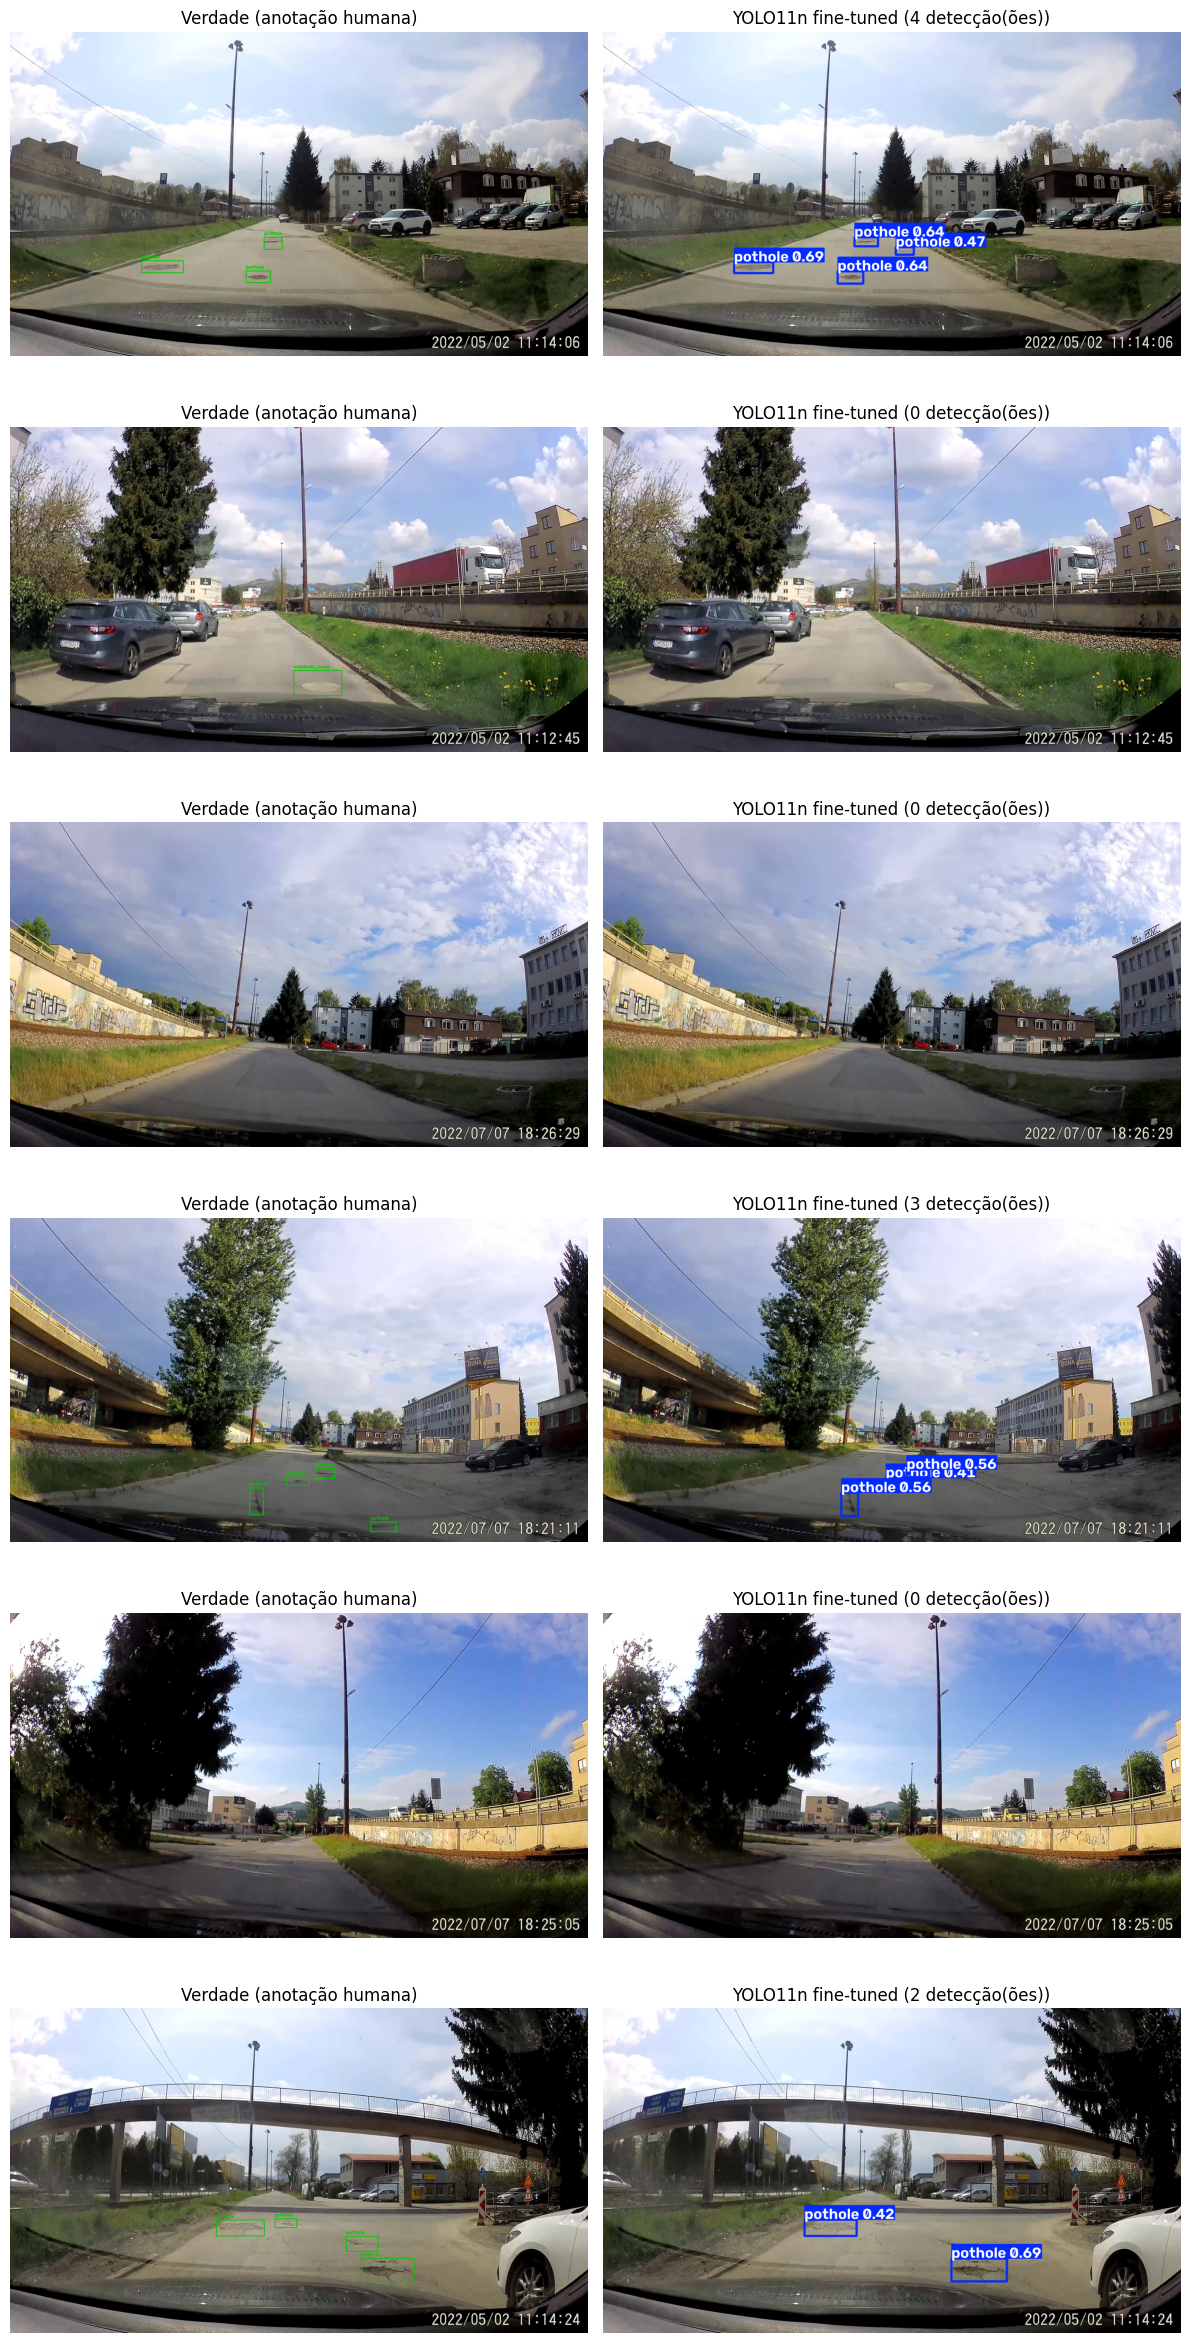

Modelo avaliado: c:\Workspace\Study\UPE\urbansense\runs\potholes-yolo11n-finetuning-v1\weights\best.pt
Limiar de confiança: 0.4
Imagens comparadas: 6
Comparação salva em: c:\Workspace\Study\UPE\urbansense\artifacts\potholes-yolo11n-finetuning-v1\comparacao_verdade_vs_previsao_v1.png


In [99]:

import cv2

CONFIDENCE_THRESHOLD = 0.40
IMAGES_TO_COMPARE = 6

test_image_dir = DATASET_DIR / "images" / "test"
image_paths = sorted(
    p for p in test_image_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not image_paths:
    raise FileNotFoundError(f"Nenhuma imagem encontrada em {test_image_dir}")

rng = random.Random(SEED)
sample_paths = rng.sample(image_paths, min(IMAGES_TO_COMPARE, len(image_paths)))


def draw_ground_truth(image_bgr, label_path):
    output = image_bgr.copy()
    h, w = output.shape[:2]

    if not label_path.exists():
        return output

    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue

        parts = line.split()
        if len(parts) != 5:
            continue

        cls = int(parts[0])
        cx, cy, bw, bh = map(float, parts[1:])

        x1 = int((cx - bw / 2) * w)
        y1 = int((cy - bh / 2) * h)
        x2 = int((cx + bw / 2) * w)
        y2 = int((cy + bh / 2) * h)

        cv2.rectangle(output, (x1, y1), (x2, y2), (0, 200, 0), 2)

        label = class_names.get(cls, str(cls))
        cv2.putText(
            output, label, (x1, max(y1 - 7, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 200, 0), 2
        )

    return output


fig, axes = plt.subplots(
    len(sample_paths), 2,
    figsize=(12, 4 * len(sample_paths))
)

if len(sample_paths) == 1:
    axes = np.array([axes])

for row, image_path in enumerate(sample_paths):
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        continue

    label_path = (
        DATASET_DIR / "labels" / "test" /
        image_path.relative_to(test_image_dir).with_suffix(".txt")
    )

    truth = draw_ground_truth(image_bgr, label_path)

    prediction = best_model.predict(
        source=image_bgr,
        conf=CONFIDENCE_THRESHOLD,
        verbose=False
    )[0]

    predicted = prediction.plot()

    axes[row, 0].imshow(cv2.cvtColor(truth, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title("Verdade (anotação humana)")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cv2.cvtColor(predicted, cv2.COLOR_BGR2RGB))
    axes[row, 1].set_title(
        f"YOLO11n fine-tuned ({len(prediction.boxes)} detecção(ões))"
    )
    axes[row, 1].axis("off")

plt.tight_layout()

comparison_path = (
    ARTIFACTS_DIR / f"comparacao_verdade_vs_previsao_v{VERSION}.png"
)
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Modelo avaliado:", BEST_WEIGHTS)
print("Limiar de confiança:", CONFIDENCE_THRESHOLD)
print("Imagens comparadas:", len(sample_paths))
print("Comparação salva em:", comparison_path)


## 10. Resultados e plano até E3

Gera um relatório inicial. Revise e complete as limitações observadas.

In [100]:

resultado_texto = f'''
# Registro do experimento — Fine-tuning inicial

Responsável: PEDRO
Data: {datetime.now().astimezone().strftime("%Y-%m-%d %H:%M:%S %Z")}
Tipo de execução: Fine-tuning inicial (YOLO11n)

## Configuração

- Modelo de origem: {BASE_MODEL}
- Pesos pré-treinados: sim
- Épocas máximas: {EPOCHS}
- Tamanho de imagem: {IMAGE_SIZE}
- Batch: {BATCH_SIZE}
- Paciência: {PATIENCE}
- Dispositivo: {DEVICE}
- Semente: {SEED}
- Dataset: {DATA_YAML}

## Resultados no conjunto de teste

- Precision: {metrics_summary["precision"]:.4f}
- Recall: {metrics_summary["recall"]:.4f}
- mAP50: {metrics_summary["mAP50"]:.4f}
- mAP50-95: {metrics_summary["mAP50_95"]:.4f}

## Análise dos resultados

Preencher após analisar:

- Distribuição e quantidade de exemplos por classe:
- Classes com poucas anotações:
- Falsos positivos observados:
- Falsos negativos observados:
- Qualidade/consistência das caixas anotadas:
- Sinais de overfitting ou underfitting nas curvas:
- Limitações de tempo/desempenho por treinamento em CPU:

## Ações para a próxima execução

1. Revisar os erros nas imagens de teste e validação, classificando falsos positivos e falsos negativos.
2. Conferir o balanceamento das classes e a quantidade de instâncias por subconjunto.
3. Auditar as anotações YOLO para identificar caixas ausentes, incorretas ou inconsistentes.
4. Ajustar hiperparâmetros com base no conjunto de validação, sem utilizar o teste para seleção.
5. Executar nova rodada identificada com outro nome, preservando esta execução.
6. Comparar os resultados utilizando as mesmas métricas e protocolo.

## Artefatos gerados

- Configuração: {config_path}
- Ambiente: {env_path}
- Dependências: {ARTIFACTS_DIR / "pip_freeze.txt"}
- Histórico de treinamento: {ARTIFACTS_DIR / "results.csv"}
- Métricas de teste: {metrics_path}
- Métricas por classe: {ARTIFACTS_DIR / "metricas_por_classe.csv"}
- Comparação visual: {comparison_path}
- Pesos ajustados: {BEST_WEIGHTS}
- Diretório do treinamento: {RUN_DIR}
'''

report_path = ARTIFACTS_DIR / f"registro_{EXPERIMENT_NAME}.md"
report_path.write_text(resultado_texto.strip() + "\n", encoding="utf-8")

print(resultado_texto)
print("\nRegistro salvo em:", report_path)


# Registro do experimento — Fine-tuning inicial

Responsável: PEDRO
Data: 2026-11-21 17:17:37 Hora Padrão de Buenos Aires
Tipo de execução: Fine-tuning inicial (YOLO11n)

## Configuração

- Modelo de origem: yolo11n.pt
- Pesos pré-treinados: sim
- Épocas máximas: 50
- Tamanho de imagem: 640
- Batch: 8
- Paciência: 10
- Dispositivo: cpu
- Semente: 42
- Dataset: c:\Workspace\Study\UPE\urbansense\data\Potholes_dataset_dividido\data.yaml

## Resultados no conjunto de teste

- Precision: 0.7027
- Recall: 0.6077
- mAP50: 0.6710
- mAP50-95: 0.2909

## Análise dos resultados

Preencher após analisar:

- Distribuição e quantidade de exemplos por classe:
- Classes com poucas anotações:
- Falsos positivos observados:
- Falsos negativos observados:
- Qualidade/consistência das caixas anotadas:
- Sinais de overfitting ou underfitting nas curvas:
- Limitações de tempo/desempenho por treinamento em CPU:

## Ações para a próxima execução

1. Revisar os erros nas imagens de teste e validação, classifi